In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score, log_loss
from sklearn.neural_network import MLPClassifier
import copy
from tqdm import tqdm

In [2]:
df_raw = pd.read_csv("data/telescope_data.csv")
df = pd.DataFrame()
df = df_raw.drop(columns=df_raw.columns[0], inplace=False)
col_names = ["fLength","fWidth","fSize","fConc","fConc1","fAsym","fM3Long","fM3Trans","fAlpha","fDist","class"]
df.columns = col_names
df['class'] = label_binarize(df['class'], classes=['h', 'g']).ravel()

In [3]:
lowE = df[df["fSize"] < 3.0]
X = lowE.drop(columns=["class","fSize"],inplace=False)
class_labels = lowE["class"]

In [4]:
gamma_flag = (class_labels == 0)
gamma_lowE = lowE[gamma_flag]
cosmic_lowE = lowE[~gamma_flag]

def plot_pdf(gamma:pd.DataFrame, cosmic:pd.DataFrame ,nbins:int, xlabel:str, scale="linear") -> None:
    title = f"PDF of {xlabel}"
    plt.hist(gamma,bins=nbins,density=True, label="Gamma")
    plt.hist(cosmic,bins=nbins,alpha=0.5 ,density=True, label="Cosmic")
    #plt.xlim(llim,hlim)
    plt.xlabel(xlabel)
    plt.ylabel("Probability Density")
    plt.title(title)
    plt.yscale(scale)
    plt.legend()
    plt.show()


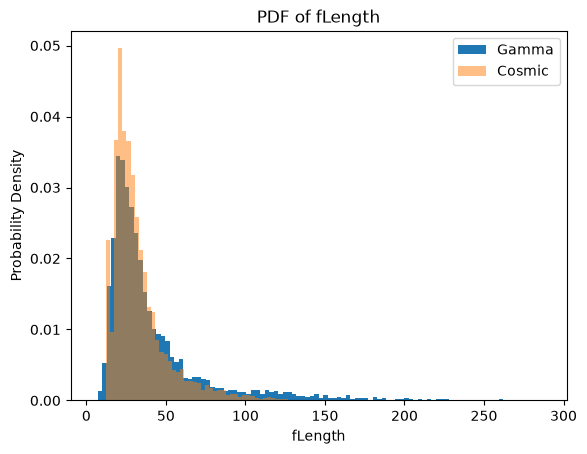

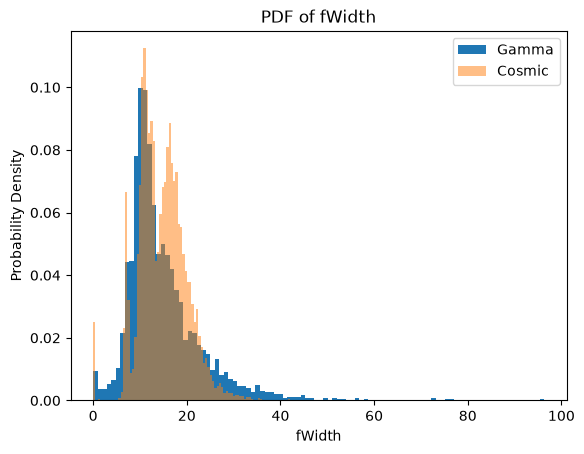

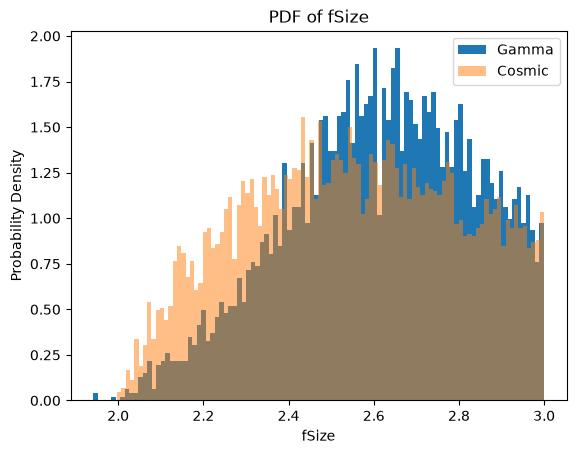

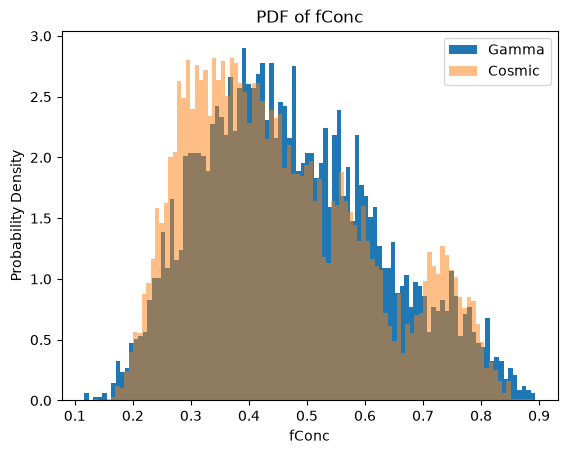

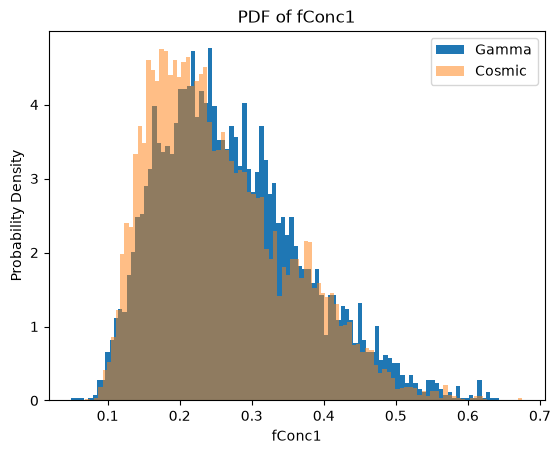

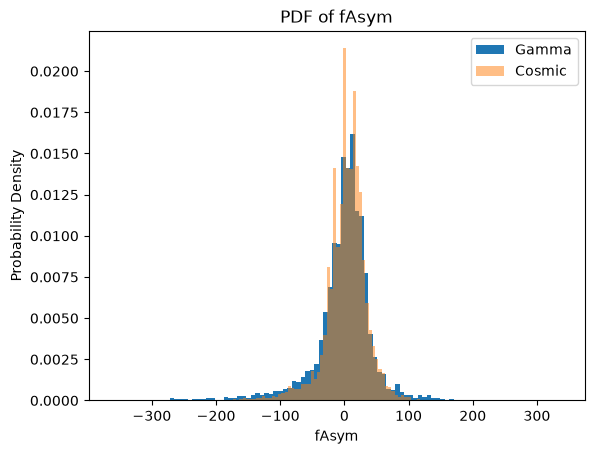

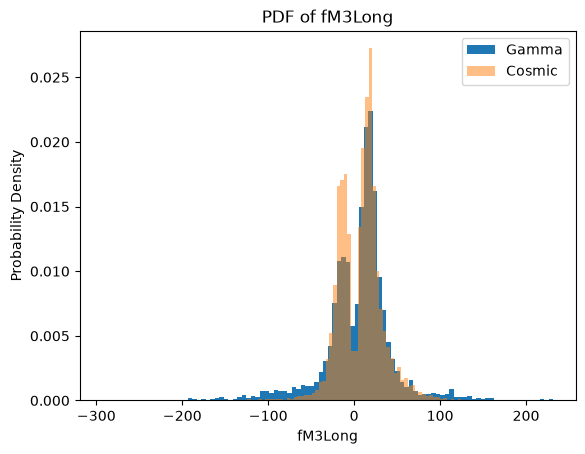

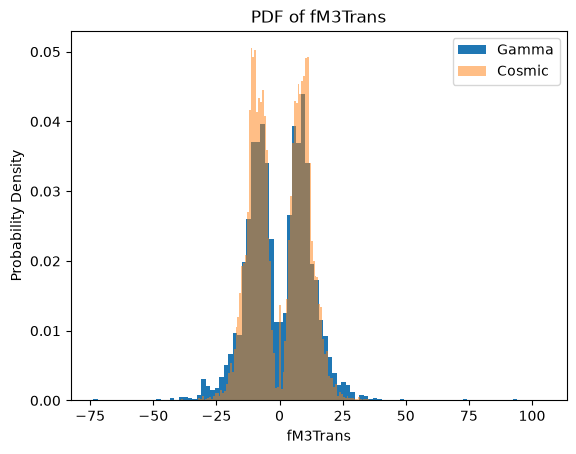

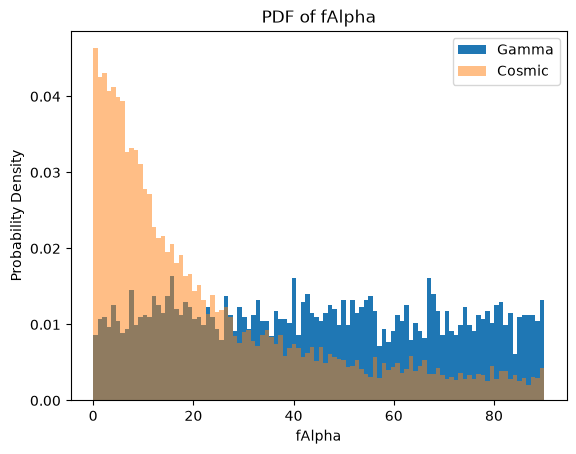

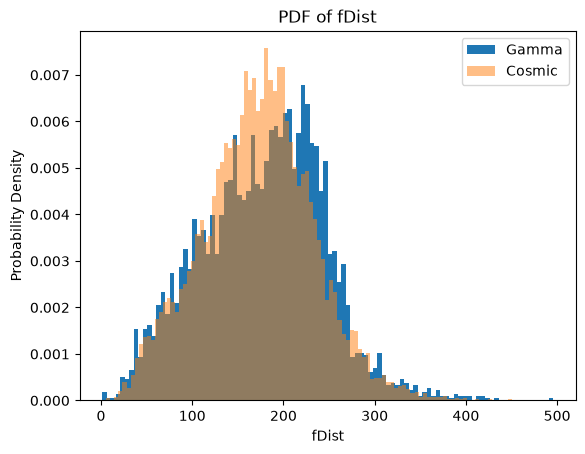

In [5]:
for col_name in lowE.columns[:-1]:
    plot_pdf(gamma_lowE[col_name], cosmic_lowE[col_name], 100, col_name)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, class_labels, test_size=0.2, random_state=1, stratify=class_labels
)

I chose to do 20% for the test size arbitrarily. I chose to do stratify as I wanted to preserve the proportion of class labels in training and testing. Gamma occurs almost twice as much as Cosmic. I chose the random_state for it to be more reporoducible.

In [7]:
best_depth = 0
best_score = 0

auc_scores_test = []
auc_scores_train = []
max_depth_min = 1
max_depth_max = 50

md_list = list(range(max_depth_min,max_depth_max))
for md in md_list:
    D_tree = DecisionTreeClassifier(max_depth=md,min_samples_leaf=64,random_state=0)
    D_tree.fit(X_train,y_train)
    
    y_prob_test = D_tree.predict_proba(X_test)[:, 1]
    y_prob_train = D_tree.predict_proba(X_train)[:, 1]
    auc_test = roc_auc_score(y_test, y_prob_test)
    auc_train = roc_auc_score(y_train, y_prob_train)
    
    auc_scores_test.append(auc_test)
    auc_scores_train.append(auc_train)
    if auc_test > best_score:
        best_score = auc_test
        best_depth = md
        
print(f"Best AUC score on test data with max_depth {best_depth}: {best_score :.3f} \n")

Best AUC score on test data with max_depth 9: 0.814 



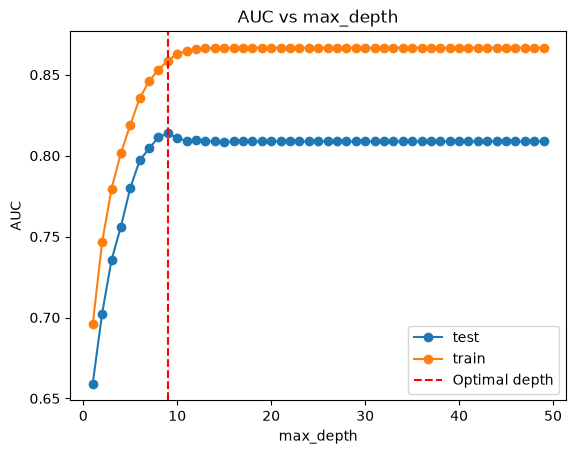

In [8]:
plt.plot(md_list, auc_scores_test, "-o", label="test")
plt.plot(md_list,auc_scores_train, "-o", label="train")
plt.xlabel("max_depth")
plt.ylabel("AUC")
plt.title("AUC vs max_depth")
plt.axvline(x=best_depth, color='red', linestyle='--', label='Optimal depth')
plt.legend()
plt.show()

The test AUC only plateaus after the best max_depth. Until then AUC on test grows. 

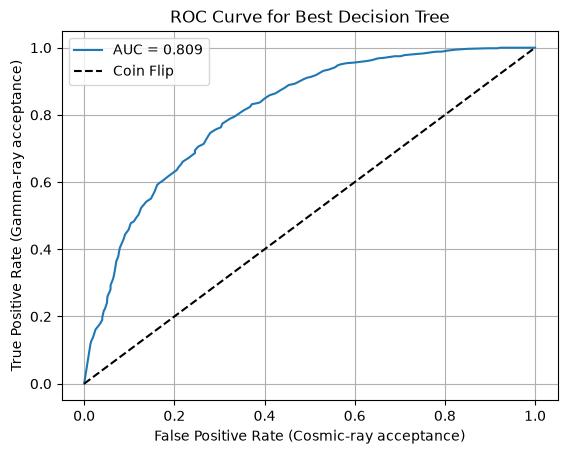

In [9]:
D_tree_best = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=64,random_state=0)
D_tree_best.fit(X_train,y_train)

y_prob_test_best = D_tree.predict_proba(X_test)[:, 1]
auc_test_best = roc_auc_score(y_test, y_prob_test_best)
fpr,tpr,_ = roc_curve(y_test,y_prob_test_best)


plt.plot(fpr, tpr, '-', label=f'AUC = {auc_test_best:.3f}')
plt.plot([0, 1], [0, 1], 'k--', label='Coin Flip')
plt.xlabel('False Positive Rate (Cosmic-ray acceptance)')
plt.ylabel('True Positive Rate (Gamma-ray acceptance)')
plt.title("ROC Curve for Best Decision Tree")
plt.legend()
plt.grid()
plt.show()

In [10]:
sorted_idx = np.argsort(D_tree.feature_importances_)
print(f"The features in order of importance were : {list(lowE.columns[sorted_idx])}")
print(f"The least important feature was : {lowE.columns[sorted_idx[-1]]}")

The features in order of importance were : ['fM3Long', 'fConc1', 'fConc', 'fAsym', 'fSize', 'fAlpha', 'fWidth', 'fLength', 'fM3Trans']
The least important feature was : fM3Trans


I would definitely keep the top 5 features and perhpas drop the last.

In [11]:
scaler = StandardScaler()
X_val, X_test2, y_val, y_test2 = train_test_split(X_test,y_test,test_size=0.5,random_state=1,stratify=y_test)
scaler.fit(X_train)
X_train_std = scaler.transform(X_train)
X_test2_std = scaler.transform(X_test2)
X_val_std = scaler.transform(X_val)

I chose a 0.8,0.1,0.1 split for train-test-val. I wanted to maximize training, this seemed like a reasonable split.

In [12]:
def iteration(hl_size, alpha=1e-3):
    clf = MLPClassifier(solver='sgd', 
                        batch_size=32, # This could be optimized too - but don't do this as part of the project.
                        activation="tanh",
                        learning_rate='constant', 
                        learning_rate_init=0.01,
                        shuffle=True, 
                        max_iter=200,
                        alpha=alpha,
                        hidden_layer_sizes=(hl_size,), 
                        random_state=1,            # For reproducibility
                        early_stopping=False,    # Do not stop! You do step by step training
                       ) 

    epochs = 300
    patience = 20
    tol = 1e-3
    
    train_loss, val_loss = [], []
    best_val, best_epoch, best_clf = np.inf, -1, None
    for epoch in range(epochs):
        clf.partial_fit(X_train_std, y_train, classes=[0, 1]) # one epoch of minibatch
        train_loss.append(log_loss(y_train, clf.predict_proba(X_train_std)[:, 1]))
        val_loss.append(log_loss(y_val, clf.predict_proba(X_val_std)[:, 1]))
    
        if val_loss[-1] < best_val - tol:   # a real improvement
            best_val, best_epoch = val_loss[-1], epoch
            best_clf = copy.deepcopy(clf) # Copy everything
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                break   

    return best_val, best_epoch, best_clf, train_loss, val_loss
    
        

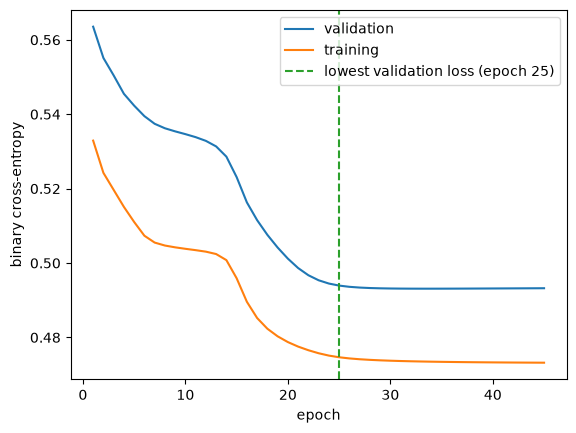

In [13]:
best_val, best_epoch, best_clf, train_loss, val_loss = iteration(2)
plt.plot(np.arange(1, np.size(val_loss) + 1), val_loss, label="validation")
plt.plot(np.arange(1, np.size(train_loss) + 1), train_loss, label="training")

plt.axvline(best_epoch + 1, color="C2", ls="--", label=f"lowest validation loss (epoch {best_epoch + 1})")
plt.xlabel("epoch")
plt.ylabel("binary cross-entropy")
plt.legend()
plt.show()

In [14]:
test_loss = log_loss(y_test2, best_clf.predict_proba(X_test2_std)[:, 1])
print(f"best epoch (from validation): {best_epoch + 1}")
print(f"validation loss at that epoch: {best_val:.4f}")
print(f"test loss at that epoch:       {test_loss:.4f}")

best epoch (from validation): 25
validation loss at that epoch: 0.4939
test loss at that epoch:       0.4957


In [15]:
size_range = list(range(2,10))
test_loss_best = np.inf
best_clf_total = None
for size in tqdm(size_range):
    _, _, best_clf_i, _, _ = iteration(size)
    test_loss_i = log_loss(y_test2, best_clf_i.predict_proba(X_test2_std)[:, 1])
    if test_loss_i < test_loss_best:
        test_loss_best = test_loss_i
        best_clf_total = copy.deepcopy(best_clf_i)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8/8 [00:28<00:00,  3.61s/it]


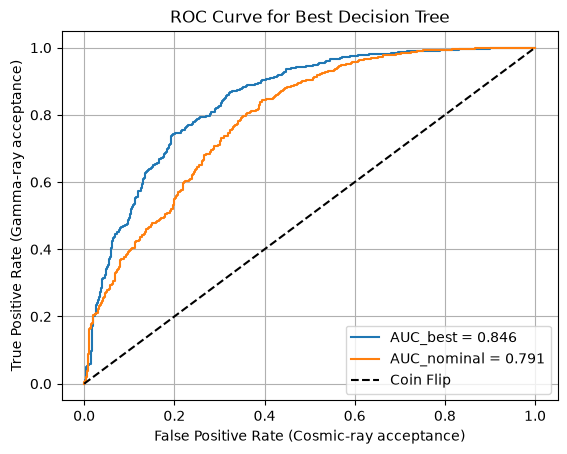

In [16]:
y_prob_val_best = best_clf_total.predict_proba(X_val_std)[:, 1]
auc_val_best = roc_auc_score(y_val, y_prob_val_best)
fpr_val,tpr_val,_ = roc_curve(y_val,y_prob_val_best)

y_prob_val_nom = best_clf.predict_proba(X_val_std)[:, 1]
auc_val_nom = roc_auc_score(y_val, y_prob_val_nom)
fpr_val_nom,tpr_val_nom,_ = roc_curve(y_val,y_prob_val_nom)


plt.plot(fpr_val, tpr_val, '-', label=f'AUC_best = {auc_val_best:.3f}')
plt.plot(fpr_val_nom, tpr_val_nom, '-', label=f'AUC_nominal = {auc_val_nom:.3f}')
plt.plot([0, 1], [0, 1], 'k--', label='Coin Flip')
plt.xlabel('False Positive Rate (Cosmic-ray acceptance)')
plt.ylabel('True Positive Rate (Gamma-ray acceptance)')
plt.title("ROC Curve for Best Decision Tree")
plt.legend()
plt.grid()
plt.show()